# KLIP forward modeling with `jighcontrast`: a planet's spectrum and the detection limits around it

PCA-based PSF subtraction (KLIP) removes a star's glare, but it also removes part
of any planet: some of the planet's light is **over-subtracted** (it projects onto
the principal components of the target image), and, because a faint planet also
appears in the reference images, some is **self-subtracted** (it leaks into the
principal components themselves). Both depend on wavelength, separation and the
number of components, so a naively measured spectrum is distorted and a naively
measured contrast curve is miscalibrated.

**KLIP forward modeling** (KLIP-FM; [Pueyo 2016, ApJ 824, 117](https://ui.adsabs.harvard.edu/abs/2016ApJ...824..117P))
computes that distortion analytically. A faint planet in the reference library is a
small perturbation of the library's covariance, so to first order its effect on
the principal components -- and therefore on the processed planet image -- is
**linear in the planet's spectrum**. One pass through the data yields a model of how
KLIP processes a planet at any spectrum, and extracting the spectrum becomes a
linear least-squares problem.

This notebook uses `jighcontrast.jFM` to:

1. forward-model how KLIP processes a companion, channel by channel;
2. extract the companion's spectrum with calibrated, wavelength-correlated
   uncertainties (Pueyo 2016, Appendix F), refining the estimate for a bright
   companion;
3. compute a forward-modeled contrast curve at a fixed false-alarm probability.

The data are a simulated 3-hour SCALES L-band (2.9-4.1 um) integral-field
sequence of HIP 21152, made with [scalesETC](https://github.com/scalessim/scalesETC):
an 8000 K star and an injected T-dwarf companion (a Sonora Bobcat model) at
390 mas.

## Setup

```bash
pip install "jighcontrast @ git+https://github.com/jordan-stone/jighcontrast"
```

The reductions below are parallel over spectral channels (`n_jobs`); each worker
uses one BLAS thread, which we request before importing numpy.

In [1]:
import os
for var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
            "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(var, "1")

import time
import urllib.request

import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

from jighcontrast import jFM

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "image.origin": "lower"})
N_JOBS = os.cpu_count()

## The data

Two files, each a `(time, wavelength, y, x)` cube of 90 exposures x 54 channels x
72 x 72 pixels (cropped about the star), with the channel wavelengths and the
parallactic angle of each exposure stored as table extensions:

* `HIP21152_SCALES_L_3h_coronagraph.fits` -- the coronagraphic ADI sequence;
* `HIP21152_SCALES_L_3h_unocculted.fits` -- the same star without the coronagraph,
  which gives the off-axis PSF (the shape of a planet's image) and the stellar flux
  that contrasts are measured against. The simulation provides an unocculted
  exposure at every parallactic angle; as in a real observing run we use only two
  snapshots, the first and the last.

They are attached to the repository's
[`example-data` release](https://github.com/jordan-stone/jighcontrast/releases/tag/example-data)
(about 100 MB each) and downloaded the first time this runs.

In [2]:
BASE_URL = "https://github.com/jordan-stone/jighcontrast/releases/download/example-data/"
FILES = {"coronagraph": "HIP21152_SCALES_L_3h_coronagraph.fits",
         "unocculted": "HIP21152_SCALES_L_3h_unocculted.fits"}
for name in FILES.values():
    if not os.path.exists(name):
        print(f"downloading {name} (~100 MB, one time only) ...")
        urllib.request.urlretrieve(BASE_URL + name, name)

with fits.open(FILES["coronagraph"]) as hdul:
    header = hdul[0].header
    coronagraph_cube = hdul[0].data.astype(float)
    wavelengths = np.asarray(hdul["WAV_MICRONS"].data["wav_microns"], float)
    parallactic_angles = np.asarray(hdul["PARANG"].data["parang_deg"], float)
with fits.open(FILES["unocculted"]) as hdul:
    snapshots = hdul[0].data.astype(float)[[0, -1]]  # before and after the sequence

star_center = (header["STARX"], header["STARY"])     # star position in the simulation (pixel centers)
pixel_scale = header["PIXSCALE"]                     # mas / pixel
telescope_diameter = header["TELDIAM"]               # m
companion_sep = header["COMPSEP"] / pixel_scale      # pixels
companion_pa = header["COMPPA"]                      # deg east of north

print("cube", coronagraph_cube.shape, "| star at", star_center,
      "| %.2f-%.2f um" % (wavelengths.min(), wavelengths.max()))
print("companion: %.1f px (%.0f mas) at PA %.0f deg; sky rotation %.0f deg"
      % (companion_sep, header["COMPSEP"], companion_pa, np.ptp(parallactic_angles)))

cube (90, 54, 72, 72) | star at (36.0, 36.0) | 2.91-4.14 um
companion: 19.5 px (390 mas) at PA 217 deg; sky rotation 108 deg


### Calibration: where the star is, and what a planet looks like

Without satellite spots there is no way to measure where the star sits behind the
coronagraph during the sequence. Its position is taken to be the coronagraph's
position on the detector -- a fixed, calibrated number (`star_center`, here where
the simulator puts the star). Tip/tilt residuals during the sequence are then an
unmodeled jitter.

The unocculted snapshots calibrate the planet model. Each is centered on its own
peak (tip/tilt differs between them), channel by channel, and the two are
combined. The plot shows where the star sat in each snapshot: in these simulated
data it drifts by about a pixel across the band -- an artifact of the simulator,
which rescales its PSF with wavelength about the array edge. Real data from
Mauna Kea are expected to drift by about a tenth of a pixel (atmospheric
dispersion; see the validation notes).

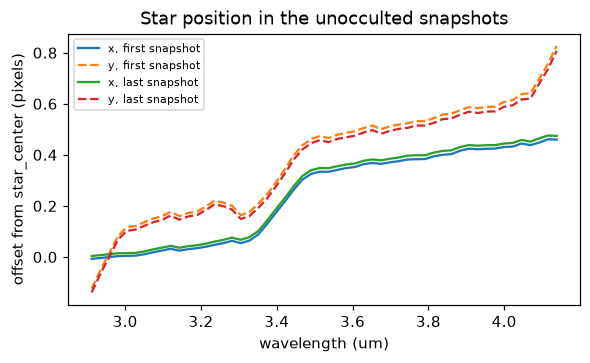

In [3]:
from jighcontrast import jPhot

fig, ax = plt.subplots(figsize=(6, 3.2))
centered = []
for label, snapshot in zip(("first", "last"), snapshots):
    peak_xy = jPhot.measure_star_centers(snapshot, star_center)
    centered.append(jPhot.register_channels(snapshot[None], peak_xy, star_center)[0])
    ax.plot(wavelengths, peak_xy[:, 0] - star_center[0], label="x, %s snapshot" % label)
    ax.plot(wavelengths, peak_xy[:, 1] - star_center[1], "--", label="y, %s snapshot" % label)
ax.set(xlabel="wavelength (um)", ylabel="offset from star_center (pixels)",
       title="Star position in the unocculted snapshots")
ax.legend(fontsize=7)
plt.show()
snapshots = np.array(centered)

The **off-axis PSF** in each channel is the median of the centered snapshots.
It sets the units of everything that follows: a source made of this PSF times `c`
has a planet-to-star flux ratio (contrast) of `c` in that channel. The PSF widens
with wavelength (lambda/D grows from 3.0 to 4.3 pixels across the band).

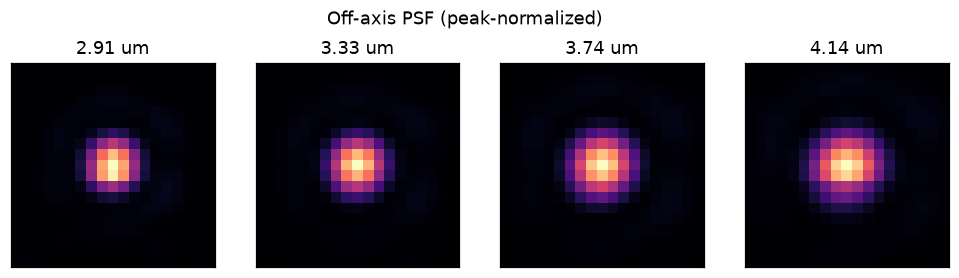

In [4]:
psf_stamps = jFM.offaxis_psf_stamps(snapshots, star_center, half=9)

fig, axes = plt.subplots(1, 4, figsize=(11, 2.9))
for ax, channel in zip(axes, [0, 18, 36, 53]):
    ax.imshow(psf_stamps[channel] / psf_stamps[channel].max(), cmap="magma")
    ax.set_title("%.2f um" % wavelengths[channel])
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Off-axis PSF (peak-normalized)")
plt.show()

## 1. How KLIP processes a companion

`jFM.klip_fm_reduce` runs a KLIP reduction around a given sky position and, in
the same pass, builds the **forward model**: the processed image of a
unit-contrast source at that position. Per Pueyo (2016) the subtraction zones are
anchored on the source (it sits in the middle of its zone in every exposure),
every exposure is reduced with references in which the source has moved by at
least 0.75 lambda/D, and the residuals are derotated and **mean**-combined -- a
linear combination, so the model stays exactly linear in the spectrum.

References are drawn from the target's own channel (ADI per channel). Without
spatially rescaling the channels to a common wavelength, other channels hold
mismatched speckle patterns; the spectral information enters later, when the
channels are combined.

The **centering** of the reference library matters: `'frame'` (each frame
zero-meaned over its zone, Pueyo's convention, the default here) makes the
forward model exact to first order; `'median'` (subtracting a median image)
leaves a neglected term worth a few percent of the flux on these data.

In [5]:
t0 = time.time()
reduction = jFM.klip_fm_reduce(
    coronagraph_cube, parallactic_angles, wavelengths, star_center,
    companion_sep, companion_pa, psf_stamps, telescope_diameter, pixel_scale,
    npca=20, n_arcs=4, exclusion_fwhm=0.75, n_jobs=N_JOBS)
print("reduced %d channels in %.0f s" % (len(wavelengths), time.time() - t0))

reduced 54 channels in 6 s


Below: the reduced data around the companion (left), the forward model of a
unit-contrast source scaled to the data (middle), and the raw PSF it started
from (right), at three wavelengths. The model reproduces KLIP's imprint: a
weakened core flanked by negative **self-subtraction lobes** along the direction
of sky rotation.

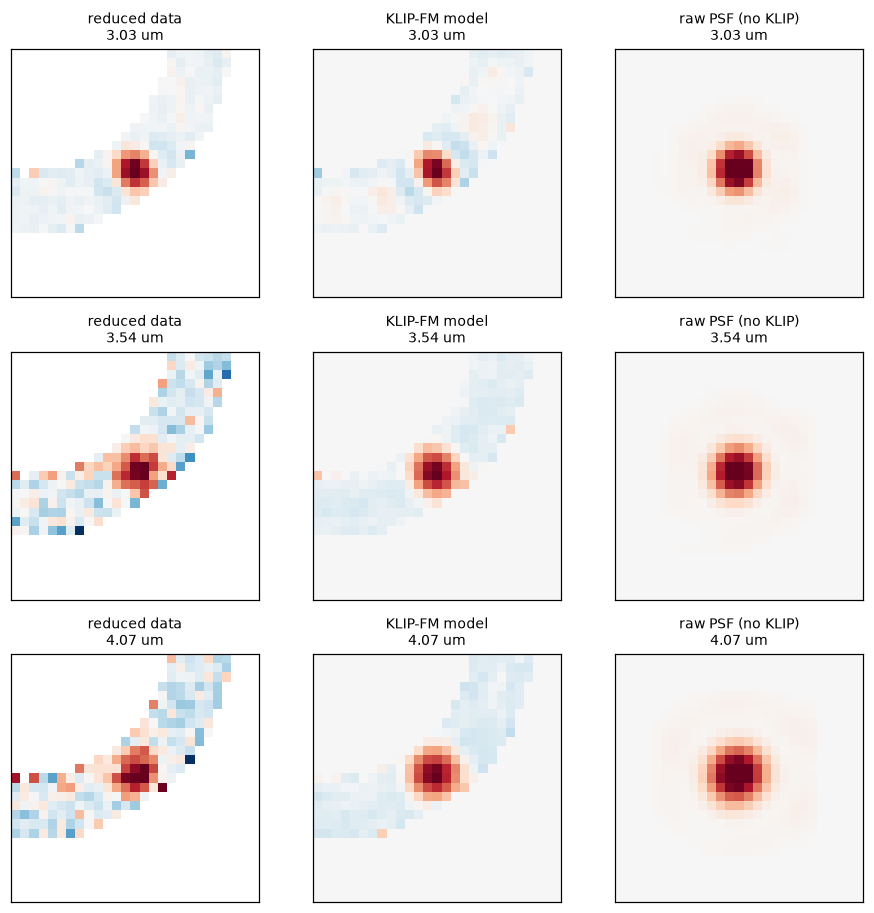

In [6]:
x0, y0 = reduction["stamp_origin"]
size = reduction["F"].shape[-1]
src_x, src_y = reduction["src_xy"]
fig, axes = plt.subplots(3, 3, figsize=(8.4, 8.4))
for row, channel in enumerate([5, 27, 50]):
    data = reduction["P"][channel][y0:y0 + size, x0:x0 + size]
    model = reduction["F"][channel, channel]
    scale = np.nansum(model * data) / np.nansum(model * model)   # best-fit contrast
    raw = jFM.place_psf(reduction["P"][channel].shape, psf_stamps[channel],
                        src_x, src_y)[y0:y0 + size, x0:x0 + size]
    vmax = np.nanmax(np.abs(scale * model))
    for ax, image, title in zip(axes[row], [data, scale * model, scale * raw],
                                ["reduced data", "KLIP-FM model", "raw PSF (no KLIP)"]):
        ax.imshow(image, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title("%s\n%.2f um" % (title, wavelengths[channel]), fontsize=9)
plt.tight_layout()
plt.show()

## 2. Extracting the spectrum

`jFM.extract_spectrum` solves Pueyo's Eq. SimpleMat: the spectrum `f` that best
explains the reduced data in a 1 lambda/D region around the companion,
`min_f  sum_p || P_p - sum_q f_q F_p[q] ||^2`, where `F_p[q]` is the processed image
in channel `p` of a unit-contrast source emitting in channel `q`. With ADI per
channel `F` is diagonal and the fit separates by channel.

**Uncertainties.** The same linear estimator is applied at empty positions
around the ring at the companion's separation: the spread of those "spectra" is
the noise, measured on the data with the actual speckle statistics. Positions one
lambda/D apart give the per-channel sigma (with the Mawet et al. 2014
small-sample correction). Speckle noise is strongly correlated across
wavelength (Greco & Brandt 2016), so the result also carries the channel
correlation (estimated from densely spaced ring positions) and the full
covariance. Any quantity derived from the spectrum -- e.g. a band-averaged
contrast -- gets its error the same way: the same combination is applied to the
ring "spectra" and their scatter is the error. (Propagating it through the
inverse covariance instead understates it severalfold near the star, where the
correlation matrix is nearly singular; see `validation/`.)

**Bright companions.** The forward model is first order in the companion's flux.
This companion (contrast ~1e-4) perturbs the principal components enough that a
single pass under-corrects the KLIP losses by several percent, which the
diagnostic `dlam_fit` (the relative eigenvalue perturbation, Pueyo 2016
App. E.3; it should be << 1) flags. `extract_spectrum` therefore refines the
estimate: it subtracts the current spectrum from the data, re-reduces, and fits
the faint remainder, where the linear model is accurate. It stops when the
updates are a small fraction of the noise. For a source this bright a handful of
channels keep moving by about one sigma from pass to pass (a small change in the
subtracted flux flips near-degenerate principal components in a few exposures);
they are listed, and their error bars should be read as a floor.

In [7]:
t0 = time.time()
extraction = jFM.extract_spectrum(
    coronagraph_cube, None, parallactic_angles, wavelengths, star_center,
    companion_sep, companion_pa, telescope_diameter, pixel_scale,
    psf_stamps=psf_stamps, npca=20, reduction=reduction, n_jobs=N_JOBS)
print("done in %.0f s" % (time.time() - t0))
print("max dlam at the companion's flux: %.2f  -> %d refinement passes"
      % (extraction["dlam_fit"].max(), extraction["n_iter"]))
print("channels still moving by > 1 sigma in the last pass:",
      wavelengths[extraction["unstable_channels"]].round(2))
broadband = extraction["broadband"]
print("band-averaged contrast %.3e +/- %.1e  (S/N %.0f, %d independent noise samples)"
      % (broadband["contrast"], broadband["sigma"], broadband["snr"], extraction["n_ring"]))

  refinement pass 1: median |update|/sigma = 0.975 (26 channels > 1 sigma)


  refinement pass 2: median |update|/sigma = 0.012 (0 channels > 1 sigma)


done in 14 s
max dlam at the companion's flux: 1.55  -> 2 refinement passes
channels still moving by > 1 sigma in the last pass: []
band-averaged contrast 1.351e-04 +/- 2.2e-06  (S/N 61, 23 independent noise samples)


Because this is a simulation we know what was injected: the companion is a Sonora
Bobcat model (Teff = 1400 K, log g = 4.5, after Franson et al. 2023) over an
8000 K PHOENIX star. The repository's `validation/data/` holds that contrast
spectrum as the simulator delivered it to each channel. For comparison we also
fit the reduced data with the *raw* PSF -- what one gets by ignoring KLIP's
distortion (in practice a throughput correction from injected fakes would partly
compensate, at the cost of many extra reductions).

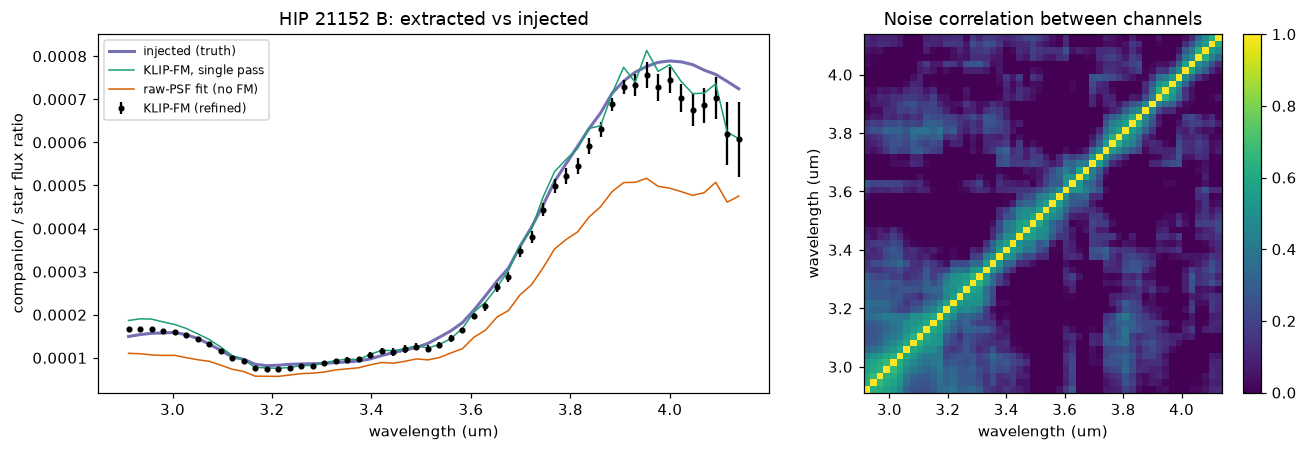

amplitude of the injected spectrum in the data: 0.982 +/- 0.013 of the truth
median raw-PSF / KLIP-FM ratio: 0.72   (the KLIP flux loss the forward model corrects)


In [8]:
TRUTH = "hip21152b_injected_contrast.csv"
local_truth = os.path.join("..", "validation", "data", TRUTH)
if not os.path.exists(local_truth):
    local_truth = TRUTH
    urllib.request.urlretrieve("https://raw.githubusercontent.com/jordan-stone/jighcontrast/"
                               "main/validation/data/" + TRUTH, TRUTH)
injected = np.loadtxt(local_truth, delimiter=",")[:, 1]

def raw_psf_spectrum(reduction):
    '''Least-squares fit of the raw PSF to the reduced data (no forward model).'''
    src_x, src_y = reduction["src_xy"]
    out = np.zeros(len(wavelengths))
    for channel in range(len(wavelengths)):
        image = reduction["P"][channel]
        psf = jFM.place_psf(image.shape, psf_stamps[channel], src_x, src_y)
        radius = jFM.resolution_element_pix(wavelengths[channel], telescope_diameter, pixel_scale)
        yy, xx = np.indices(image.shape)
        region = (np.hypot(xx - src_x, yy - src_y) <= radius) & np.isfinite(image)
        out[channel] = np.sum(psf[region] * image[region]) / np.sum(psf[region] ** 2)
    return out

naive_spectrum = raw_psf_spectrum(reduction)
spectrum, sigma = extraction["spectrum"], extraction["sigma"]

fig, (ax, ax_corr) = plt.subplots(1, 2, figsize=(12, 4.2),
                                  gridspec_kw=dict(width_ratios=[1.6, 1]))
ax.plot(wavelengths, injected, "-", color="#7570b3", lw=2, label="injected (truth)")
ax.errorbar(wavelengths, spectrum, sigma, fmt="o", ms=3, color="k", label="KLIP-FM (refined)")
ax.plot(wavelengths, extraction["history"][0], "-", color="#1b9e77", lw=1,
        label="KLIP-FM, single pass")
ax.plot(wavelengths, naive_spectrum, "-", color="#d95f02", lw=1, label="raw-PSF fit (no FM)")
ax.set(xlabel="wavelength (um)", ylabel="companion / star flux ratio",
       title="HIP 21152 B: extracted vs injected")
ax.legend(fontsize=8)
image = ax_corr.imshow(extraction["corr"], cmap="viridis", vmin=0, vmax=1,
                       extent=[wavelengths[0], wavelengths[-1], wavelengths[0], wavelengths[-1]])
ax_corr.set(xlabel="wavelength (um)", ylabel="wavelength (um)",
            title="Noise correlation between channels")
plt.colorbar(image, ax=ax_corr, fraction=0.046)
plt.tight_layout()
plt.show()

fit = jFM.broadband_contrast(extraction, spectrum_shape=injected / injected.mean())
print("amplitude of the injected spectrum in the data: %.3f +/- %.3f of the truth"
      % (fit["contrast"] / injected.mean(), fit["sigma"] / injected.mean()))
print("median raw-PSF / KLIP-FM ratio: %.2f   (the KLIP flux loss the forward model corrects)"
      % np.median(naive_spectrum / spectrum))

The extraction follows the injected spectrum through the methane trough near
3.3 um and up to the 4 um peak. The very last channels sit slightly above it:
in this simulation the band-edge channels pick up some light from other
wavelengths through the simulated spectrograph's rectification (cross-talk that
the truth curve includes only approximately).

`jFM.broadband_contrast` fits any spectral shape to the extraction with
generalized least squares (weights from the covariance) and returns its
amplitude and an empirically calibrated error, as used just above. The chi^2 it
also returns compares shapes but relies on the covariance and is indicative only.

## 3. Detection limits

The same forward model calibrates a contrast curve. `jFM.contrast_curve`, at
each separation:

* reduces the annulus (fixed subtraction zones) and forward-models a
  unit-contrast probe at several azimuths, so the KLIP throughput is known
  without injecting fake planets;
* fits that forward-modeled template at independent lambda/D positions around
  the ring -- the fitted amplitude is in contrast units (a **matched filter**);
* quotes the limit at a **fixed false-alarm probability** (that of a Gaussian
  5 sigma), using the Student-t small-sample statistics of Mawet et al. (2014):
  few independent samples at small separations raise the threshold.

`jFM.combine_contrast_empirical` combines channels for an assumed spectral shape
by applying the combination to the matched-filter amplitudes at common ring
positions and measuring the scatter of the result. For comparison,
`jFM.combine_contrast` assumes the channels are independent.

First, remove the companion. Left in, a bright companion's KLIP self-subtraction
arcs -- negative imprints spread over the sky rotation at its separation -- sit
in the noise rings and inflate the limits there. Its extracted spectrum is a
complete model of it, so subtracting that from every exposure (a negative
injection) removes it; its own position is still excluded from the rings to
absorb what the PSF model cannot describe.

In [9]:
separations = np.arange(8.0, 29.0, 2.0)
t0 = time.time()
companion_free_cube = jFM.inject_source(coronagraph_cube, psf_stamps, parallactic_angles,
                                        star_center, companion_sep, companion_pa,
                                        -extraction["spectrum"])
curve = jFM.contrast_curve(
    companion_free_cube, None, parallactic_angles, wavelengths, star_center,
    separations, telescope_diameter, pixel_scale, npca=20, n_arcs=4, n_probe=8,
    centering="frame", known_companion=(companion_pa, companion_sep),
    comp_exclude_fwhm=2.5, psf_stamps=psf_stamps, n_jobs=N_JOBS, verbose=False)
print("contrast curve in %.0f s" % (time.time() - t0))

_, contrast_independent = jFM.combine_contrast(curve)
_, contrast_limit, n_ring = jFM.combine_contrast_empirical(curve)

contrast curve in 118 s


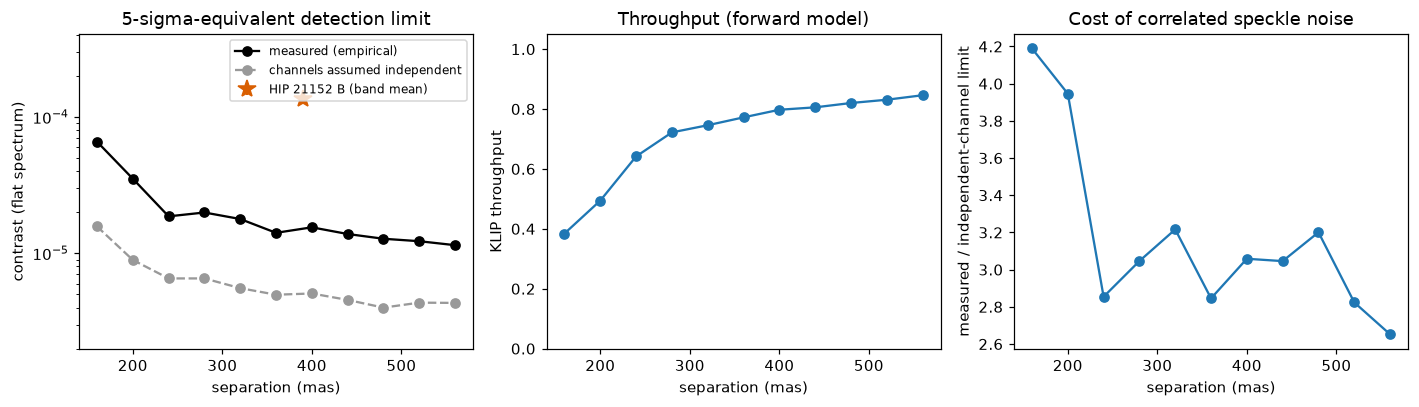

In [10]:
sep_mas = separations * pixel_scale
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
ax = axes[0]
ax.plot(sep_mas, contrast_limit, "o-", color="k", label="measured (empirical)")
ax.plot(sep_mas, contrast_independent, "o--", color="0.6", label="channels assumed independent")
ax.errorbar(header["COMPSEP"], broadband["contrast"], 3 * broadband["sigma"], fmt="*",
            ms=12, color="#d95f02", label="HIP 21152 B (band mean)")
ax.set(yscale="log", xlabel="separation (mas)", ylabel="contrast (flat spectrum)",
       title="5-sigma-equivalent detection limit",
       ylim=(0.5 * np.nanmin(contrast_independent), 3 * broadband["contrast"]))
ax.legend(fontsize=8, loc="upper right")
axes[1].plot(sep_mas, np.nanmedian(curve["tau"], axis=1), "o-")
axes[1].set(xlabel="separation (mas)", ylabel="KLIP throughput", ylim=(0, 1.05),
            title="Throughput (forward model)")
axes[2].plot(sep_mas, contrast_limit / contrast_independent, "o-")
axes[2].set(xlabel="separation (mas)", ylabel="measured / independent-channel limit",
            title="Cost of correlated speckle noise")
plt.tight_layout()
plt.show()

Combining the 54 channels does not gain the factor of sqrt(54) ~ 7 that
independent channels would: speckle noise is correlated across wavelength, most
strongly close to the star, so assuming independence makes the curve look
several times deeper than it is. The limit is also quoted at a fixed
false-alarm probability, so it rises at small separations where a ring holds
only a handful of independent resolution elements.

## Caveats

* **Star position.** One fixed star position is assumed for all channels and
  exposures. Any drift of the star with wavelength or time (dispersion, tip/tilt
  residuals) is unmodeled; in these simulated data the simulator's ~1 pixel
  chromatic drift tilts the extracted spectrum toward the band edges.
* **Position.** The extraction assumes the companion's position is known (to a
  fraction of a pixel); astrometry is not fitted.
* **First-order validity.** Check `dlam_fit`. The validation in
  [`validation/`](../validation) shows the single-pass model is accurate to
  better than 1% for `dlam_fit` up to ~0.1 and that refinement recovers unbiased
  spectra for brighter sources.
* **Coronagraph transmission** off-axis is taken as 1 (the unocculted PSF is the
  planet model); include it in `psf_stamps` if it is not.